# Практическая работа № 1. Первичный осмотр датасета «tips»

**Цель:** развернуть окружение и выполнить первичную загрузку и осмотр учебного датасета.

**План:**
1. Загрузка данных
2. Структура таблицы: размер, типы, пропуски, базовые статистики
3. Визуализация
4. Наблюдения о данных

In [2]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 120)

## 1. Загрузка данных

Файл лежит в `data/tips.csv`. Если его там нет, он один раз скачивается из репозитория seaborn и сохраняется в `data/`.

In [3]:
DATA_PATH = Path("../data/tips.csv")

if not DATA_PATH.exists():
    DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    sns.load_dataset("tips").to_csv(DATA_PATH, index=False)

df = pd.read_csv(DATA_PATH)
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


## 2. Структура таблицы

In [4]:
print("Размер таблицы (строк, столбцов):", df.shape)
print()
print("Типы столбцов:")
print(df.dtypes)
print()
print("Число пропусков по столбцам:")
print(df.isna().sum())

Размер таблицы (строк, столбцов): (244, 7)

Типы столбцов:
total_bill    float64
tip           float64
sex               str
smoker            str
day               str
time              str
size            int64
dtype: object

Число пропусков по столбцам:
total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64


In [5]:
# Базовые статистики числовых признаков
df.describe()

,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


In [6]:
# Категориальные признаки: число уникальных значений, самое частое, его частота
df.describe(exclude="number")

,sex,smoker,day,time
count,244,244,244,244
unique,2,2,4,2
top,Male,No,Sat,Dinner
freq,157,151,87,176


## 3. Визуализация

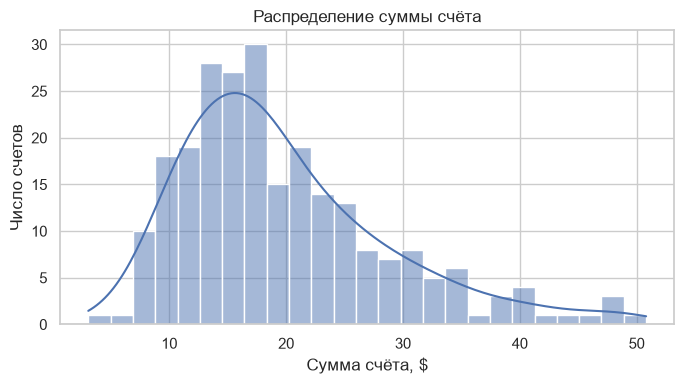

In [7]:
# График 1. Распределение числового признака: сумма счёта
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(df["total_bill"], bins=25, kde=True, ax=ax)
ax.set_title("Распределение суммы счёта")
ax.set_xlabel("Сумма счёта, $")
ax.set_ylabel("Число счетов")
plt.tight_layout()
plt.show()

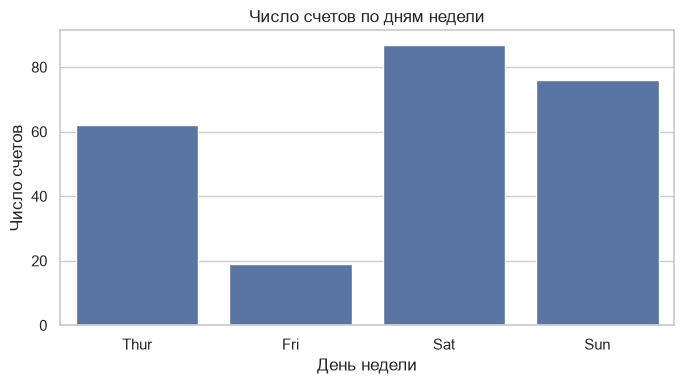

In [8]:
# График 2. Соотношение категорий: число счетов по дням недели
day_order = ["Thur", "Fri", "Sat", "Sun"]

fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=df, x="day", order=day_order, ax=ax)
ax.set_title("Число счетов по дням недели")
ax.set_xlabel("День недели")
ax.set_ylabel("Число счетов")
plt.tight_layout()
plt.show()

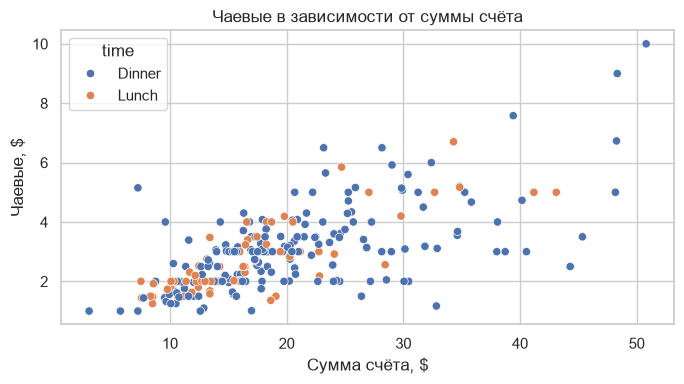

In [9]:
# График 3. Связь двух числовых признаков: сумма счёта и чаевые
fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=df, x="total_bill", y="tip", hue="time", ax=ax)
ax.set_title("Чаевые в зависимости от суммы счёта")
ax.set_xlabel("Сумма счёта, $")
ax.set_ylabel("Чаевые, $")
plt.tight_layout()
plt.show()

## 4. Наблюдения о данных

Ниже считаются числа, на которые опираются наблюдения. Ни одно из них не повторяет вывод `describe()`.

In [10]:
# Доля чаевых от счёта — производный признак
df["tip_pct"] = df["tip"] / df["total_bill"] * 100

print("Доля чаевых от счёта, %:")
print(df["tip_pct"].describe().round(1))
print()
print("Корреляция суммы счёта и чаевых:", round(df["total_bill"].corr(df["tip"]), 2))
print("Корреляция суммы счёта и доли чаевых:", round(df["total_bill"].corr(df["tip_pct"]), 2))
print()
print("Доля счетов по размеру компании, %:")
print((df["size"].value_counts(normalize=True).sort_index() * 100).round(1))
print()
print("Число счетов по дням, %:")
print((df["day"].value_counts(normalize=True).reindex(day_order) * 100).round(1))
print()
print("Средняя доля чаевых по дням, %:")
print(df.groupby("day")["tip_pct"].mean().reindex(day_order).round(1))

Доля чаевых от счёта, %:
count    244.0
mean      16.1
std        6.1
min        3.6
25%       12.9
50%       15.5
75%       19.1
max       71.0
Name: tip_pct, dtype: float64

Корреляция суммы счёта и чаевых: 0.68
Корреляция суммы счёта и доли чаевых: -0.34

Доля счетов по размеру компании, %:
size
1     1.6
2    63.9
3    15.6
4    15.2
5     2.0
6     1.6
Name: proportion, dtype: float64

Число счетов по дням, %:
day
Thur    25.4
Fri      7.8
Sat     35.7
Sun     31.1
Name: proportion, dtype: float64

Средняя доля чаевых по дням, %:
day
Thur    16.1
Fri     17.0
Sat     15.3
Sun     16.7
Name: tip_pct, dtype: float64


**Наблюдения (черновик — сверить с выводом ячейки выше и подставить свои числа):**

1. **Чаевые пропорциональны счёту, а не фиксированы.** Сумма чаевых растёт вместе со счётом (диаграмма рассеяния), при этом доля чаевых от счёта держится около одного и того же уровня, а корреляция суммы счёта с долей чаевых близка к нулю.
2. **Данные несбалансированы по дням недели.** Основная масса счетов приходится на выходные (суббота и воскресенье), а в пятницу наблюдений заметно меньше всего. Выводы по пятнице опираются на малую выборку.
3. **Типичный посетитель — компания из двух человек, а распределение счёта скошено вправо.** Большинство счетов относится к размеру компании 2; у суммы счёта длинный правый хвост из редких крупных счетов, поэтому среднее выше типичного значения.

Пропусков в данных нет, очистка не требуется.